In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Configure the Retro Synthwave color palette and global plotting style
def set_synthwave_palette(style="whitegrid", context="notebook", font_family="sans-serif"):
    palette = ['#f72585', '#b5179e', '#7209b7', '#560bad', '#480ca8',
               '#3a0ca3', '#3f37c9', '#4361ee', '#4895ef', '#4cc9f0']

    sns.set_palette(palette)
    sns.set_style(style)
    sns.set_context(context)

    plt.rcParams.update({
        'axes.titlepad': 20,
        'axes.titlesize': 14,
        'axes.labelsize': 12,
        'font.family': font_family,
        'figure.autolayout': True,
        'axes.edgecolor': '#3a0ca3',  # Dark purple border
        'axes.facecolor': '#ffffff',  # White axes background
        'figure.facecolor': '#ffffff',  # White figure background
        'axes.labelcolor': '#3a0ca3',  # Dark purple axis labels
        'axes.titlecolor': '#3a0ca3',  # Dark purple title
        'xtick.color': '#3a0ca3',  # Dark purple x-axis tick labels
        'ytick.color': '#3a0ca3',
        'grid.color': '#4cc9f0',  # Light blue grid
        'grid.alpha': 0.5
    })

    return palette
palette = set_synthwave_palette()

# Exploratory data analysis

C:\Users\user\AppData\Local\Temp\ipykernel_12944\4008393177.py:51: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


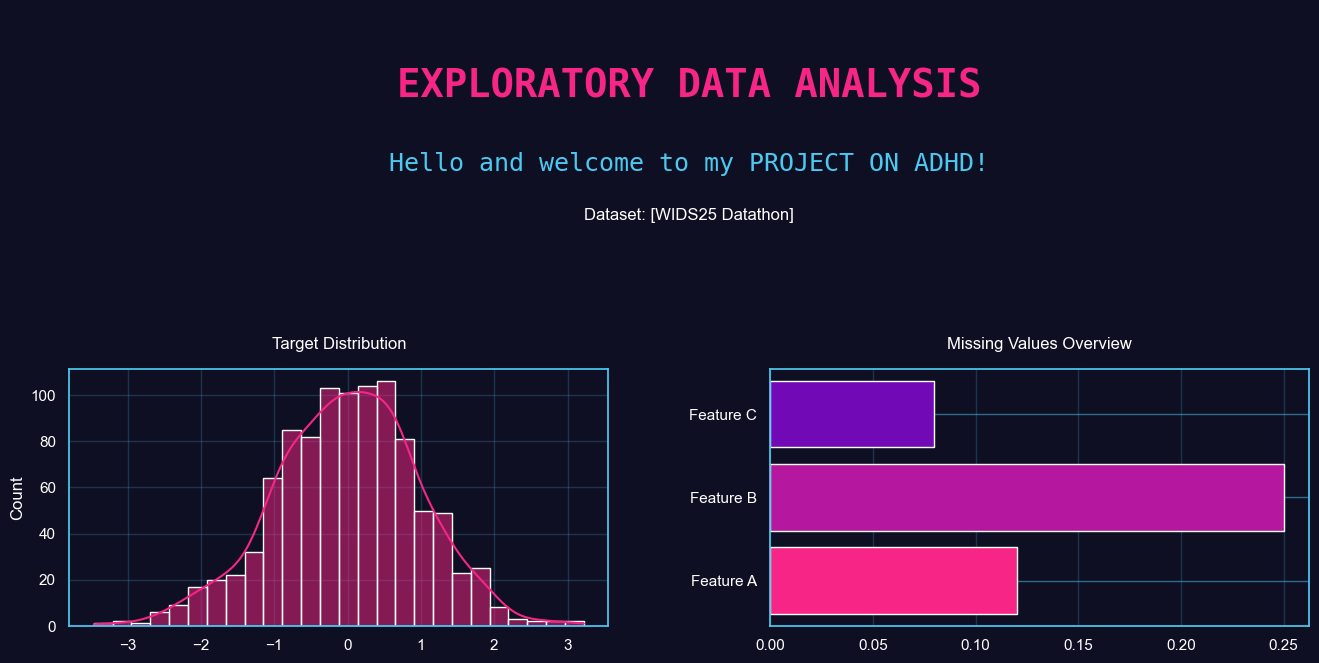

In [2]:
from matplotlib.gridspec import GridSpec

plt.figure(figsize=(16, 8), facecolor='#0f0f23')

# Create grid layout
gs = GridSpec(2, 2, figure=plt.gcf(), hspace=0.4, wspace=0.3)

# Title box
ax_title = plt.subplot(gs[0, :])
ax_title.set_facecolor('#0f0f23')
ax_title.text(0.5, 0.7, 'EXPLORATORY DATA ANALYSIS',
             fontsize=28, ha='center', va='center',
             color='#f72585', fontweight='bold',
             fontfamily='monospace')
ax_title.text(0.5, 0.4, 'Hello and welcome to my PROJECT ON ADHD!',
             fontsize=18, ha='center', va='center',
             color='#4cc9f0', fontfamily='monospace')
ax_title.text(0.5, 0.2, 'Dataset: [WIDS25 Datathon]',
             fontsize=12, ha='center', va='center',
             color='white')
ax_title.axis('off')

# Sample distribution plot
ax1 = plt.subplot(gs[1, 0])
sns.histplot(np.random.normal(0, 1, 1000),
             kde=True, color='#f72585', ax=ax1)
ax1.set_title('Target Distribution',
              pad=15, color='white', fontsize=12)
ax1.set_facecolor('#0f0f23')
ax1.grid(color='#4cc9f0', alpha=0.2)

# Missing values placeholder
ax2 = plt.subplot(gs[1, 1])
missing_bars = ax2.barh(['Feature A', 'Feature B', 'Feature C'],
                        [0.12, 0.25, 0.08],
                        color=['#f72585', '#b5179e', '#7209b7'])
ax2.set_title('Missing Values Overview',
              pad=15, color='white', fontsize=12)
ax2.set_facecolor('#0f0f23')
ax2.grid(color='#4cc9f0', alpha=0.2, axis='x')

# Apply styling to all axes
for ax in [ax1, ax2]:
    for spine in ax.spines.values():
        spine.set_edgecolor('#4cc9f0')
    ax.tick_params(colors='white', which='both')
    ax.xaxis.label.set_color('white')
    ax.yaxis.label.set_color('white')

plt.suptitle('', fontsize=1)
plt.tight_layout()
plt.show()

# Loading training and test datasets

In [3]:
import numpy as np
import pandas as pd

# Load training datasets
solutions_metrics_data = pd.read_excel(r"C:\Users\user\Desktop\Python\TRAIN_NEW\TRAINING_SOLUTIONS.xlsx")
categorical_metrics_data = pd.read_excel(r"C:\Users\user\Desktop\Python\TRAIN_NEW\TRAIN_CATEGORICAL_METADATA_new.xlsx")
metrics_data = pd.read_csv(r"C:\Users\user\Desktop\Python\TRAIN_NEW\TRAIN_FUNCTIONAL_CONNECTOME_MATRICES_new_36P_Pearson.csv")
quantitative_metrics_data = pd.read_excel(r"C:\Users\user\Desktop\Python\TRAIN_NEW\TRAIN_QUANTITATIVE_METADATA_new.xlsx")
# Load test datasets
categorical_metrics_test_data = pd.read_excel(r"C:\Users\user\Desktop\Python\TEST\TEST_CATEGORICAL.xlsx")
metrics_test_data = pd.read_csv(r"C:\Users\user\Desktop\Python\TEST\TEST_FUNCTIONAL_CONNECTOME_MATRICES.csv")
quantitative_metrics_test_data = pd.read_excel(r"C:\Users\user\Desktop\Python\TEST\TEST_QUANTITATIVE_METADATA.xlsx")

# Checking the data types

In [4]:
print(solutions_metrics_data.dtypes)
print(categorical_metrics_data.dtypes)
print(quantitative_metrics_data.dtypes)
print(categorical_metrics_test_data.dtypes)
print(quantitative_metrics_test_data.dtypes)

participant_id    object
ADHD_Outcome       int64
Sex_F              int64
dtype: object
participant_id                       object
Basic_Demos_Enroll_Year               int64
Basic_Demos_Study_Site                int64
PreInt_Demos_Fam_Child_Ethnicity    float64
PreInt_Demos_Fam_Child_Race         float64
MRI_Track_Scan_Location             float64
Barratt_Barratt_P1_Edu              float64
Barratt_Barratt_P1_Occ              float64
Barratt_Barratt_P2_Edu              float64
Barratt_Barratt_P2_Occ              float64
dtype: object
participant_id                 object
EHQ_EHQ_Total                 float64
ColorVision_CV_Score          float64
APQ_P_APQ_P_CP                float64
APQ_P_APQ_P_ID                float64
APQ_P_APQ_P_INV               float64
APQ_P_APQ_P_OPD               float64
APQ_P_APQ_P_PM                float64
APQ_P_APQ_P_PP                float64
SDQ_SDQ_Conduct_Problems      float64
SDQ_SDQ_Difficulties_Total    float64
SDQ_SDQ_Emotional_Problems    float64
S

In [5]:
# Missing value analysis
def create_missing_values_df(merged_df, df_names):

    # Perform missing-value analysis
    null_counts = merged_df.isnull().sum()
    total_rows = len(merged_df)
    null_percent = (null_counts / total_rows) * 100

    # Identify the source dataset of each column
    origin_mapping = {}
    for name, df in zip(df_names, dfs_to_merge):
        for col in df.columns:
            if col != 'participant_id':
                origin_mapping[col] = name

    # Create the results DataFrame
    result_df = pd.DataFrame({
        'Column_Name': null_counts.index,
        'Dataset_Origin': [origin_mapping.get(col, 'Merged') for col in null_counts.index],
        'Missing_Count': null_counts.values,
        'Missing_Percentage': null_percent.round(2).values
    })

    return result_df
# Merge training datasets
dfs_to_merge = [solutions_metrics_data, categorical_metrics_data, quantitative_metrics_data]
train_names = ["Solutions Metrics", "Categorical Metrics", "Quantitative Metrics"]
# Merge datasets using participant_id
merged_train = dfs_to_merge[0]
for df in dfs_to_merge[1:]:
    merged_train = pd.merge(merged_train, df, on='participant_id', how='outer')
missing_values_train_df = create_missing_values_df(merged_train, train_names)
# Merge test datasets
test_dfs = [categorical_metrics_test_data, quantitative_metrics_test_data]
test_names = ["Categorical Metrics Test", "Quantitative Metrics Test"]
merged_test = test_dfs[0]
for df in test_dfs[1:]:
    merged_test = pd.merge(merged_test, df, on='participant_id', how='outer')
missing_values_test_df = create_missing_values_df(merged_test, test_names)
# Display the results
print("MISSING VALUES IN TRAINING DATA")
print(missing_values_train_df)
print("\n\n MISSING VALUES IN TEST DATA")
print(missing_values_test_df)

MISSING VALUES IN TRAINING DATA
                         Column_Name        Dataset_Origin  Missing_Count  \
0                     participant_id                Merged              0   
1                       ADHD_Outcome     Solutions Metrics              0   
2                              Sex_F     Solutions Metrics              0   
3            Basic_Demos_Enroll_Year   Categorical Metrics              0   
4             Basic_Demos_Study_Site   Categorical Metrics              0   
5   PreInt_Demos_Fam_Child_Ethnicity   Categorical Metrics             43   
6        PreInt_Demos_Fam_Child_Race   Categorical Metrics             54   
7            MRI_Track_Scan_Location   Categorical Metrics              3   
8             Barratt_Barratt_P1_Edu   Categorical Metrics             15   
9             Barratt_Barratt_P1_Occ   Categorical Metrics             31   
10            Barratt_Barratt_P2_Edu   Categorical Metrics            198   
11            Barratt_Barratt_P2_Occ   Categ

C:\Users\user\AppData\Local\Temp\ipykernel_12944\2231778910.py:6: UserWarning: The palette list has more values (10) than needed (4), which may not be intended.
  ax = sns.barplot(x='Missing_Percentage', y='Column_Name', hue='Dataset_Origin',


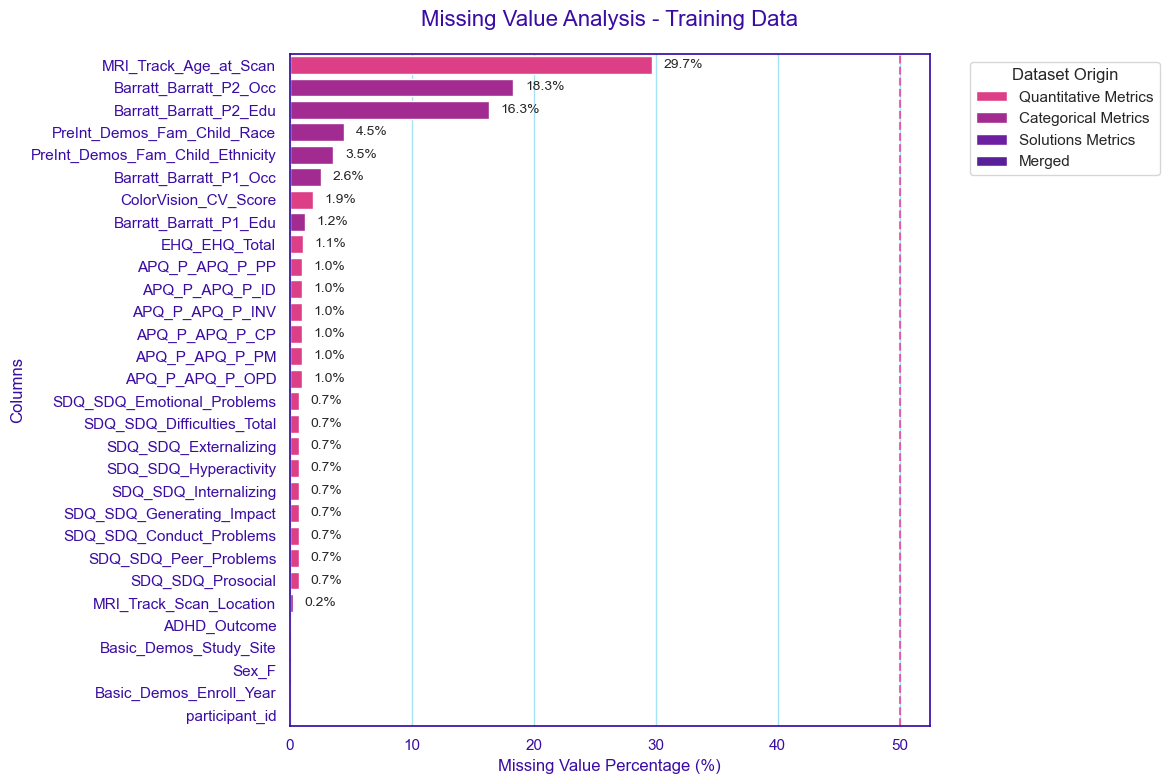

C:\Users\user\AppData\Local\Temp\ipykernel_12944\2231778910.py:6: UserWarning: The palette list has more values (10) than needed (2), which may not be intended.
  ax = sns.barplot(x='Missing_Percentage', y='Column_Name', hue='Dataset_Origin',


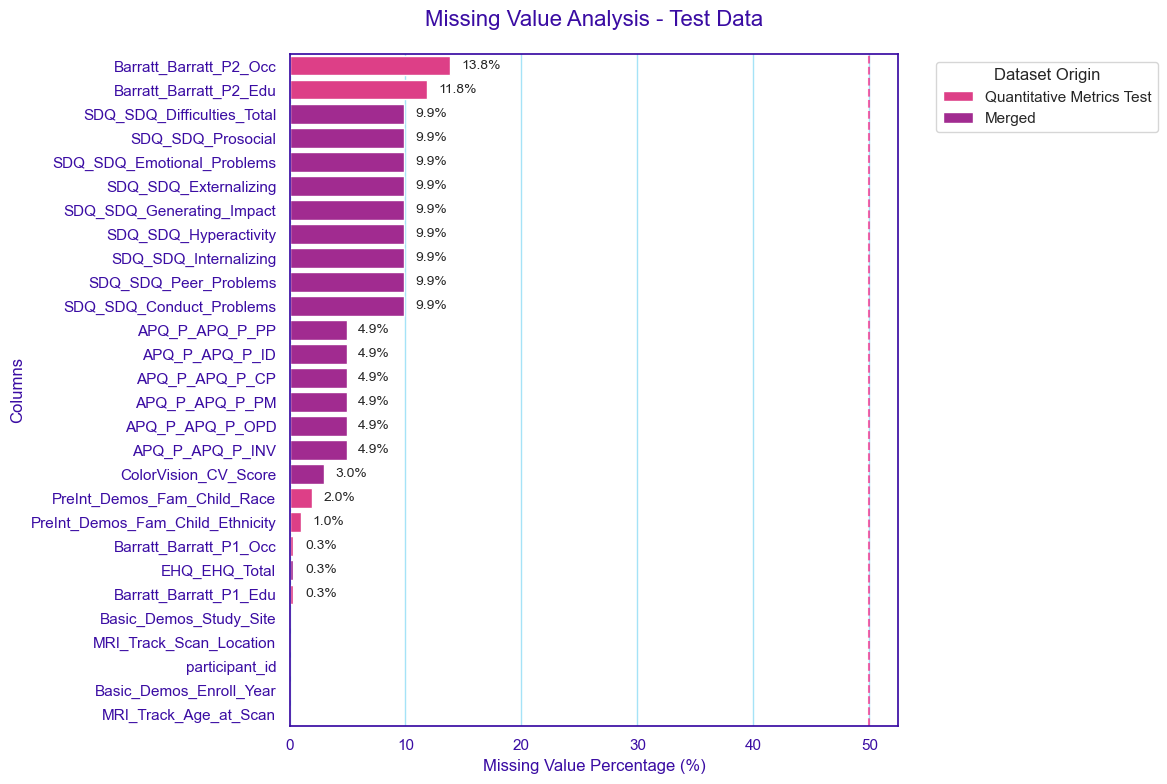

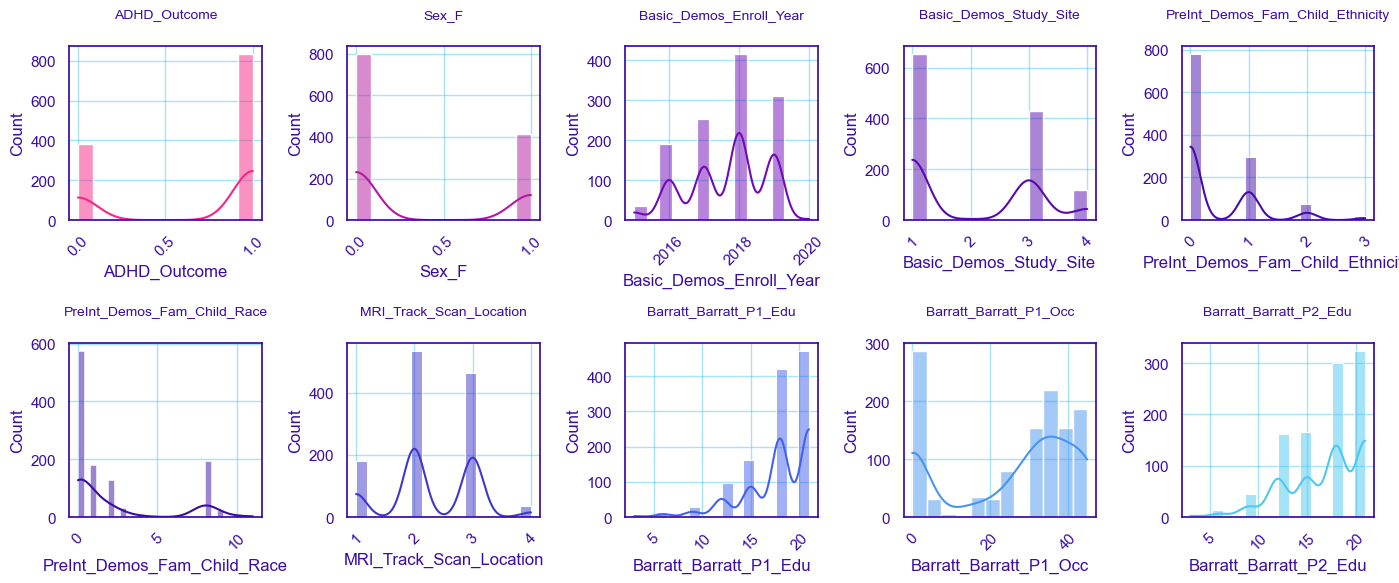

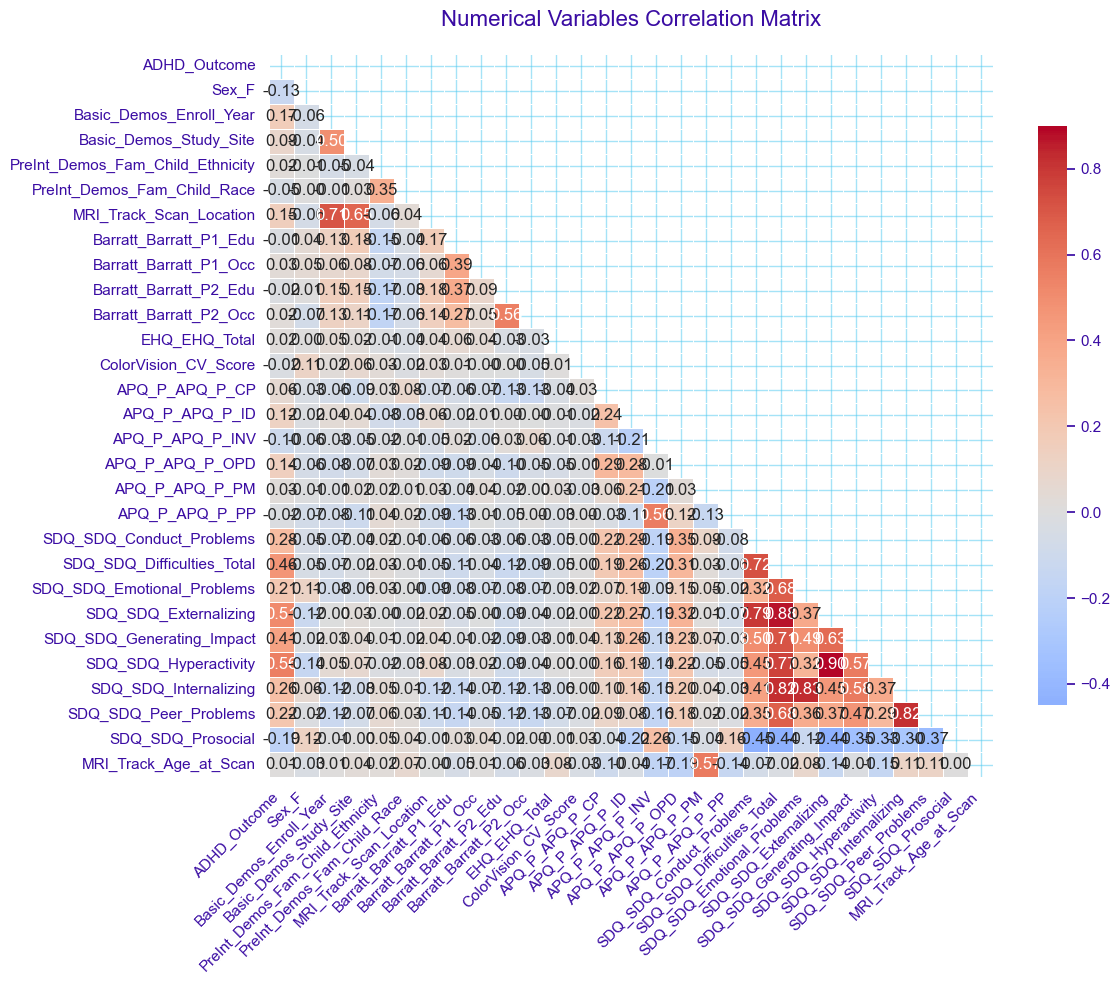

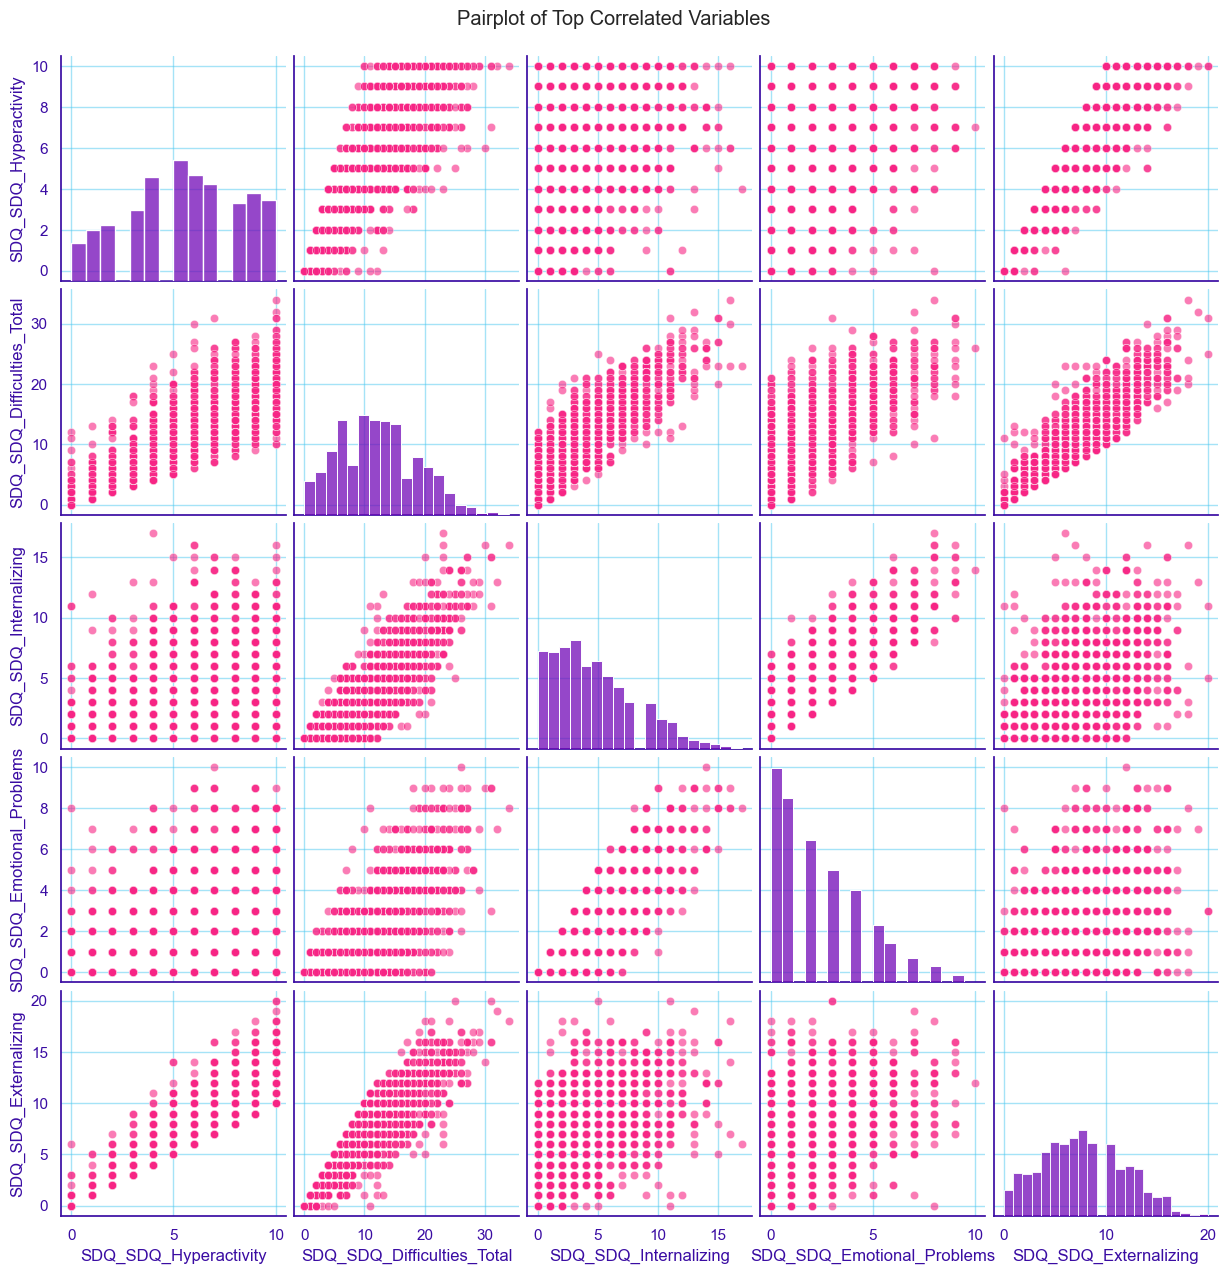

In [6]:
# Visualizing missing values and exploring data distribution
def visualize_missing_data(missing_df, title):
    missing_df = missing_df.sort_values('Missing_Percentage', ascending=False)

    plt.figure(figsize=(12, 8))
    ax = sns.barplot(x='Missing_Percentage', y='Column_Name', hue='Dataset_Origin',
                     data=missing_df, palette=palette, dodge=False)

    plt.title(f'Missing Value Analysis - {title}', fontsize=16, pad=20)
    plt.xlabel('Missing Value Percentage (%)', fontsize=12)
    plt.ylabel('Columns', fontsize=12)
    plt.axvline(x=50, color='#f72585', linestyle='--', alpha=0.7)

    for p in ax.patches:
        width = p.get_width()
        if width > 0:
            ax.text(width + 1, p.get_y() + p.get_height()/2.,
                    f'{width:.1f}%',
                    ha='left', va='center', fontsize=10)

    plt.legend(title='Dataset Origin', bbox_to_anchor=(1.05, 1), loc='upper left')
    plt.tight_layout()
    plt.show()
visualize_missing_data(missing_values_train_df, "Training Data")
visualize_missing_data(missing_values_test_df, "Test Data")
numerical_cols = [col for col in merged_train.select_dtypes(include=np.number).columns
                  if col != 'participant_id']
if len(numerical_cols) > 0:
    plt.figure(figsize=(14, 6))
    for i, col in enumerate(numerical_cols[:10]):  
        plt.subplot(2, 5, i+1)
        sns.histplot(merged_train[col], kde=True, color=palette[i%len(palette)])
        plt.title(col, fontsize=10)
        plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()
categorical_cols = [col for col in merged_train.select_dtypes(exclude=np.number).columns
                    if col != 'participant_id']
if len(categorical_cols) > 0:
    plt.figure(figsize=(14, 6))
    for i, col in enumerate(categorical_cols[:5]):
        plt.subplot(1, 5, i+1)
        sns.countplot(y=col, data=merged_train,
                      order=merged_train[col].value_counts().index,
                      color=palette[i%len(palette)])
        plt.title(col, fontsize=10)
        plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()
if len(numerical_cols) > 1:
    plt.figure(figsize=(12, 10))
    corr_matrix = merged_train[numerical_cols].corr()
    mask = np.triu(np.ones_like(corr_matrix, dtype=bool))

    sns.heatmap(corr_matrix, mask=mask, annot=True, fmt=".2f",
                cmap='coolwarm', center=0, linewidths=.5,
                cbar_kws={"shrink": .8})

    plt.title('Numerical Variables Correlation Matrix', fontsize=16, pad=20)
    plt.xticks(rotation=45, ha='right')
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()
if len(numerical_cols) > 1:
    top_corr_vars = corr_matrix.abs().unstack().sort_values(ascending=False)
    top_corr_vars = top_corr_vars[top_corr_vars < 1].index[:5]
    selected_cols = list(set([x[0] for x in top_corr_vars] + [x[1] for x in top_corr_vars]))

    sns.pairplot(merged_train[selected_cols],
                 plot_kws={'alpha': 0.6, 'color': palette[0]},
                 diag_kws={'color': palette[2]})
    plt.suptitle('Pairplot of Top Correlated Variables', y=1.02)
    plt.show()

# Preprocessing categorical and numerical variables

In [7]:
# Define categorical and numerical column lists
categorical_cols = [
    'Basic_Demos_Enroll_Year', 'Basic_Demos_Study_Site',
    'PreInt_Demos_Fam_Child_Ethnicity', 'PreInt_Demos_Fam_Child_Race',
    'MRI_Track_Scan_Location', 'Barratt_Barratt_P1_Edu',
    'Barratt_Barratt_P1_Occ', 'Barratt_Barratt_P2_Edu',
    'Barratt_Barratt_P2_Occ'
]
numerical_cols = [
    'EHQ_EHQ_Total', 'ColorVision_CV_Score', 'APQ_P_APQ_P_CP',
    'APQ_P_APQ_P_ID', 'APQ_P_APQ_P_INV', 'APQ_P_APQ_P_OPD',
    'APQ_P_APQ_P_PM', 'APQ_P_APQ_P_PP', 'SDQ_SDQ_Difficulties_Total',
    'SDQ_SDQ_Conduct_Problems', 'SDQ_SDQ_Emotional_Problems',
    'SDQ_SDQ_Externalizing', 'SDQ_SDQ_Generating_Impact',
    'SDQ_SDQ_Hyperactivity', 'SDQ_SDQ_Internalizing',
    'SDQ_SDQ_Peer_Problems', 'SDQ_SDQ_Prosocial', 'MRI_Track_Age_at_Scan'
]
def preprocess_data(train_df, test_df, categorical_cols, numerical_cols):

    train_processed = train_df.copy()
    test_processed = test_df.copy()

    # Handle missing values in categorical columns
    for col in categorical_cols:
        if col in train_processed.columns:

            train_processed[col] = train_processed[col].astype(str).replace('nan', 'MISSING')

            # Replace test categories not found in training data with 'MISSING'
            if col in test_processed.columns:
                test_processed[col] = test_processed[col].astype(str).replace('nan', 'MISSING')
                unique_train_cats = set(train_df[col].dropna().astype(str).unique())
                test_processed[col] = test_processed[col].apply(
                    lambda x: x if x in unique_train_cats else 'MISSING')

    # Handle missing values in numerical columns
    for col in numerical_cols:
        if col in train_processed.columns:
            min_val = train_processed[col].min()

            if min_val < -500:
                print(f"Warning: Column {col} contains values below -500 ({min_val}). "
                      f"Missing values could not be imputed for this column.")
            else:
                fill_value = -999
                train_processed[col] = train_processed[col].fillna(fill_value)

                if col in test_processed.columns:
                    test_processed[col] = test_processed[col].fillna(fill_value)

    return train_processed, test_processed
train_processed, test_processed = preprocess_data(
    merged_train, merged_test, categorical_cols, numerical_cols
)

In [8]:
# checking remaining missing values
def check_missing_values(train_df, test_df, categorical_cols, numerical_cols):

    print("MISSING-VALUE CHECK: TRAINING DATA")

    # Categorical columns
    print("\nCategorical Columns:")
    cat_missing_train = train_df[categorical_cols].isnull().sum()
    print(cat_missing_train[cat_missing_train > 0])

    # Numerical columns
    print("\nNumerical Columns:")
    num_missing_train = train_df[numerical_cols].isnull().sum()
    print(num_missing_train[num_missing_train > 0])

    print("\n\n MISSING-VALUE CHECK: TEST DATA")

    # Categorical columns
    print("\nCategorical Columns:")
    cat_missing_test = test_df[categorical_cols].isnull().sum()
    print(cat_missing_test[cat_missing_test > 0])

    # Numerical columns
    print("\nNumerical Columns:")
    num_missing_test = test_df[numerical_cols].isnull().sum()
    print(num_missing_test[num_missing_test > 0])

    # Summary report
    print("\n\n SUMMARY REPORT")
    print(f"Total missing values in training data: {train_df.isnull().sum().sum()}")
    print(f"Total missing values in test data: {test_df.isnull().sum().sum()}")
check_missing_values(train_processed, test_processed, categorical_cols, numerical_cols)

MISSING-VALUE CHECK: TRAINING DATA

Categorical Columns:
Series([], dtype: int64)

Numerical Columns:
Series([], dtype: int64)


 MISSING-VALUE CHECK: TEST DATA

Categorical Columns:
Series([], dtype: int64)

Numerical Columns:
Series([], dtype: int64)


 SUMMARY REPORT
Total missing values in training data: 0
Total missing values in test data: 0


# Visualizing and analyzing one participant's brain connectivity matrix

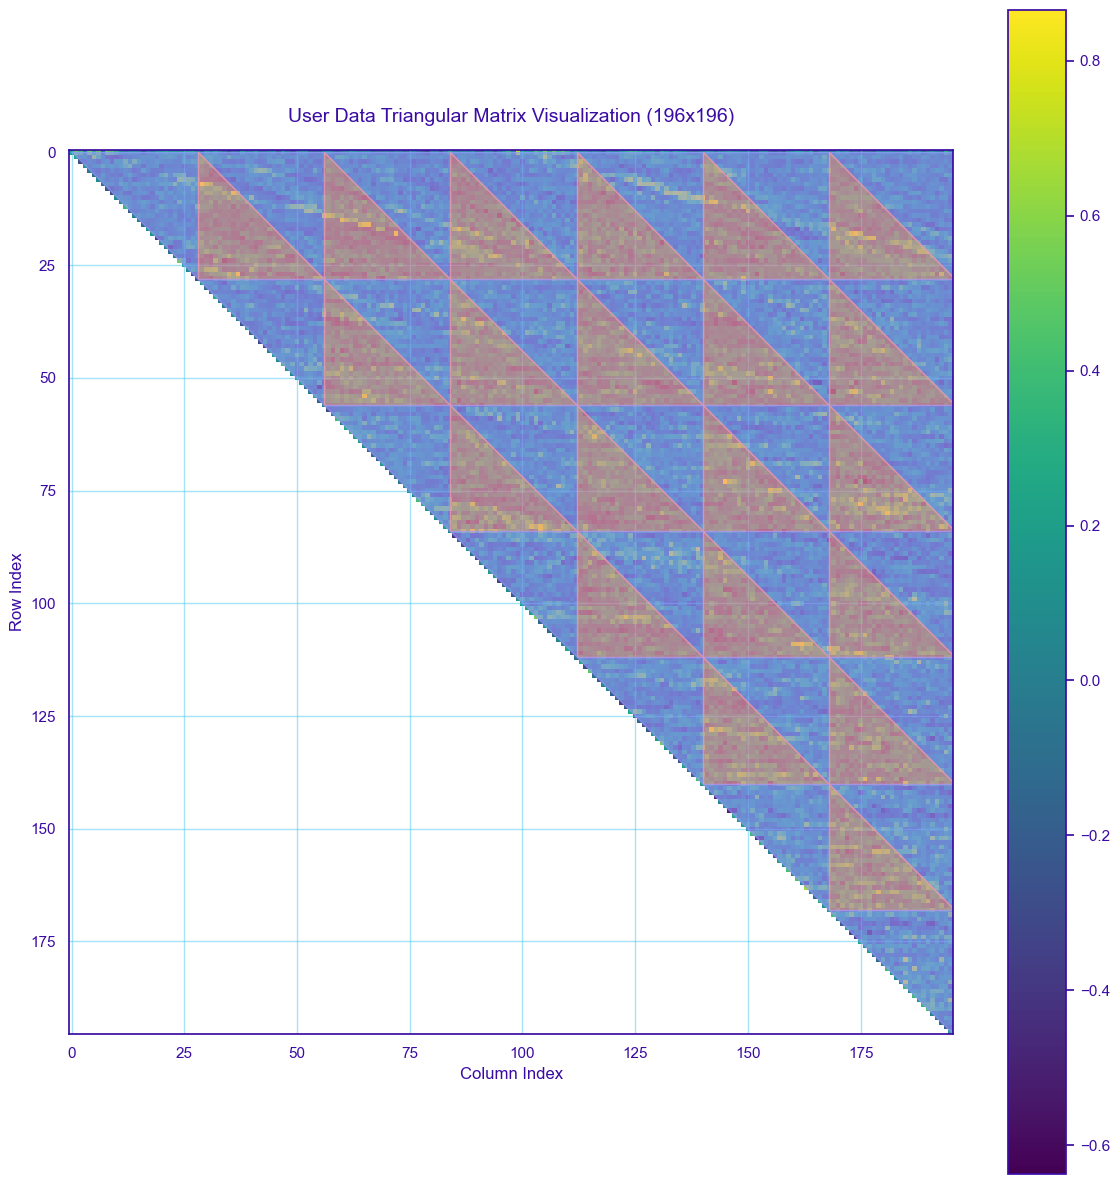

Triangle 1 - Region: Alt | Positive Connections: 1 | Negative Connections: 1 | Positive Proportion: 0.00 | Negative Proportion: 0.00 | Positive-to-Negative Ratio: 1.00
Triangle 2 - Region: Alt | Positive Connections: 17 | Negative Connections: 11 | Positive Proportion: 0.02 | Negative Proportion: 0.01 | Positive-to-Negative Ratio: 1.55
Triangle 2 - Region: Üst | Positive Connections: 18 | Negative Connections: 15 | Positive Proportion: 0.02 | Negative Proportion: 0.02 | Positive-to-Negative Ratio: 1.20
Triangle 3 - Region: Alt | Positive Connections: 12 | Negative Connections: 25 | Positive Proportion: 0.02 | Negative Proportion: 0.03 | Positive-to-Negative Ratio: 0.48
Triangle 3 - Region: Üst | Positive Connections: 10 | Negative Connections: 14 | Positive Proportion: 0.01 | Negative Proportion: 0.02 | Positive-to-Negative Ratio: 0.71
Triangle 4 - Region: Alt | Positive Connections: 18 | Negative Connections: 14 | Positive Proportion: 0.02 | Negative Proportion: 0.02 | Positive-to-Neg

In [9]:
import matplotlib.pyplot as plt

# Define general parameters
GRID_SIZE = 28  # Size of each square block
MATRIX_SIZE = 196  # Size of the connectivity matrix
UPPER_TRIANGLE_COLOR = (1.0, 0.6, 0.6, 0.6)  # Light red for the upper triangle
LOWER_TRIANGLE_COLOR = (0.6, 0.6, 1.0, 0.6)  # Light blue for the lower triangle
EXCLUDE_TRIANGLE_INDICES = {1, 8, 14, 19, 23, 26, 28}  # Triangle indices to exclude

THRESHOLDS = {
    "positive": 0.44,  # Positive correlation threshold
    "negative": -0.34  # Negative correlation threshold
}


# Function to calculate connectivity statistics for each triangle
def calculate_triangle_statistics(triangle_values, triangle_index, region):

    total_values = len(triangle_values)

    pos_values = np.sum(triangle_values > THRESHOLDS["positive"])
    neg_values = np.sum(triangle_values < THRESHOLDS["negative"])

    pos_ratio = pos_values / total_values if total_values > 0 else np.nan
    neg_ratio = neg_values / total_values if total_values > 0 else np.nan
    pos_neg_ratio = pos_values / neg_values if neg_values > 0 else np.nan

    stats = {
        "Üçgen No": triangle_index,
        "Bölge": region,
        "Pozitif Sayısı": pos_values,
        "Negatif Sayısı": neg_values,
        "Pozitif Oran": pos_ratio,
        "Negatif Oran": neg_ratio,
        "Pozitif/Negatif Oran": pos_neg_ratio
    }

    return stats


###############################################################################
# Retrieve the first participant's data for an example visualisation

first_user_metrics_data = metrics_data.iloc[0, 1:].values  # First participant's data, excluding the first column

# Create an empty 196 x 196 matrix filled with NaN values
matrix = np.full((MATRIX_SIZE, MATRIX_SIZE), np.nan)

start_index = 0

for i in range(MATRIX_SIZE):
    num_columns = MATRIX_SIZE - i

    if num_columns > 0:
        matrix[i, i:i + num_columns] = first_user_metrics_data[start_index:start_index + num_columns]

    start_index += num_columns


plt.figure(figsize=(12, 12))
plt.imshow(matrix, cmap='viridis', interpolation='nearest')
plt.colorbar()
plt.title("User Data Triangular Matrix Visualization (196x196)")
plt.xlabel("Column Index")
plt.ylabel("Row Index")


# Divide the matrix into blocks and colour their upper and lower triangles
triangle_statistics = []
triangle_index = 1

for i in range(0, MATRIX_SIZE - GRID_SIZE + 1, GRID_SIZE):

    for j in range(i, MATRIX_SIZE - GRID_SIZE + 1, GRID_SIZE):

        if j >= i:

            square = matrix[i:i + GRID_SIZE, j:j + GRID_SIZE]

            upper_triangle = np.triu(square)
            lower_triangle = np.tril(square)

            upper_triangle_values = upper_triangle[np.isfinite(upper_triangle)]
            lower_triangle_values = lower_triangle[np.isfinite(lower_triangle)]

            # Check whether the current block lies on the main diagonal
            is_diagonal = (i == j)

            # Calculate lower-triangle statistics
            # Include diagonal blocks and non-excluded blocks
            if is_diagonal or (triangle_index not in EXCLUDE_TRIANGLE_INDICES):

                stats_lower = calculate_triangle_statistics(
                    lower_triangle_values, triangle_index, "Alt"
                )

                triangle_statistics.append(stats_lower)

                plt.gca().add_patch(
                    plt.Polygon(
                        [[j, i], [j + GRID_SIZE, i], [j + GRID_SIZE, i + GRID_SIZE]],
                        color=LOWER_TRIANGLE_COLOR
                    )
                )

            # Calculate upper-triangle statistics
            # Only include blocks that are not on the main diagonal
            if not is_diagonal:

                stats_upper = calculate_triangle_statistics(
                    upper_triangle_values, triangle_index, "Üst"
                )

                triangle_statistics.append(stats_upper)

                plt.gca().add_patch(
                    plt.Polygon(
                        [[j, i], [j, i + GRID_SIZE], [j + GRID_SIZE, i + GRID_SIZE]],
                        color=UPPER_TRIANGLE_COLOR
                    )
                )

            triangle_index += 1
plt.show()
# Display the calculated connectivity statistics
all_statistics = []
for stats in triangle_statistics:

    stat_line = (
        f"Triangle {stats['Üçgen No']} - Region: {stats['Bölge']} | "
        f"Positive Connections: {stats['Pozitif Sayısı']} | "
        f"Negative Connections: {stats['Negatif Sayısı']} | "
        f"Positive Proportion: {stats['Pozitif Oran']:.2f} | "
        f"Negative Proportion: {stats['Negatif Oran']:.2f} | "
        f"Positive-to-Negative Ratio: {stats['Pozitif/Negatif Oran']:.2f}"
    )

    all_statistics.append(stat_line)

print("\n".join(all_statistics))
df_statistics = pd.DataFrame(triangle_statistics)
columns = []
for i in range(1, 29):

    if i in EXCLUDE_TRIANGLE_INDICES and i != 1:
        columns.append(f"Üçgen {i} - Üst")

    else:
        columns.append(f"Üçgen {i} - Alt")

        if i != 1:
            columns.append(f"Üçgen {i} - Üst")
df_final = pd.DataFrame(index=df_statistics.columns[2:], columns=columns)
# Add the calculated statistics as rows
for col in columns:

    triangle_no, region = col.split(" - ")
    triangle_no = int(triangle_no.split()[1])

    region_stats = df_statistics[
        (df_statistics["Üçgen No"] == triangle_no) &
        (df_statistics["Bölge"] == region)
    ].drop(columns=["Üçgen No", "Bölge"])

    if not region_stats.empty:
        df_final[col] = region_stats.values.flatten()

# Calculating connectivity statistics for all training participants

In [10]:
import numpy as np
import pandas as pd
from tqdm import tqdm

# Define general parameters
MATRIX_SIZE = 196  # Size of the connectivity matrix
GRID_SIZE = 28  # Size of each square block
EXCLUDE_TRIANGLE_INDICES = {1, 8, 14, 19, 23, 26, 28}  # Triangle indices to exclude

THRESHOLDS = {
    "positive": 0.44,
    "negative": -0.34
}


# Function to calculate connectivity statistics for each triangle
def calculate_triangle_statistics(triangle_values, triangle_index, region, participant_id):

    total_values = len(triangle_values)

    pos_values = np.sum(triangle_values > THRESHOLDS["positive"])
    neg_values = np.sum(triangle_values < THRESHOLDS["negative"])

    pos_ratio = pos_values / total_values if total_values > 0 else np.nan
    neg_ratio = neg_values / total_values if total_values > 0 else np.nan
    pos_neg_ratio = pos_values / neg_values if neg_values > 0 else np.nan

    stats = {
        "Kullanıcı ID": participant_id,
        "Üçgen No - Bölge": f"{triangle_index} - {region}",
        "Pozitif Sayısı": pos_values,
        "Negatif Sayısı": neg_values,
        "Pozitif Oran": pos_ratio,
        "Negatif Oran": neg_ratio,
        "Pozitif/Negatif Oran": pos_neg_ratio
    }

    return stats
# Create a list to store connectivity statistics for all participants
all_users_statistics = []
# Process the connectivity data for each participant
for user_id in tqdm(range(len(metrics_data)), desc="Processing participants"):

    user_metrics_data = metrics_data.iloc[user_id, 1:].values
    participant_id = categorical_metrics_data['participant_id'].iloc[user_id]

    user_metrics_data = pd.to_numeric(user_metrics_data, errors='coerce')

    # Create an empty matrix filled with NaN values
    matrix = np.full((MATRIX_SIZE, MATRIX_SIZE), np.nan)

    start_index = 0

    for i in range(MATRIX_SIZE):

        num_columns = MATRIX_SIZE - i

        if num_columns > 0:
            matrix[i, i:i + num_columns] = user_metrics_data[start_index:start_index + num_columns]

        start_index += num_columns


    # Divide the connectivity matrix into smaller blocks
    triangle_statistics = []
    triangle_index = 1

    for i in range(0, MATRIX_SIZE - GRID_SIZE + 1, GRID_SIZE):

        for j in range(i, MATRIX_SIZE - GRID_SIZE + 1, GRID_SIZE):

            if j >= i:

                square = matrix[i:i + GRID_SIZE, j:j + GRID_SIZE]

                upper_triangle = np.triu(square)
                lower_triangle = np.tril(square)

                upper_triangle_values = upper_triangle[np.isfinite(upper_triangle)]
                lower_triangle_values = lower_triangle[np.isfinite(lower_triangle)]

                # Calculate statistics for the lower triangle
                if triangle_index not in EXCLUDE_TRIANGLE_INDICES:

                    stats_lower = calculate_triangle_statistics(
                        lower_triangle_values,
                        triangle_index,
                        "Alt",
                        participant_id
                    )

                    triangle_statistics.append(stats_lower)

                # Calculate statistics for the upper triangle
                stats_upper = calculate_triangle_statistics(
                    upper_triangle_values,
                    triangle_index,
                    "Üst",
                    participant_id
                )

                triangle_statistics.append(stats_upper)

                triangle_index += 1

    all_users_statistics.extend(triangle_statistics)
df_all_statistics = pd.DataFrame(all_users_statistics)
# Combine the calculated statistics for each participant
all_users_combined_stats = []
for user_id in range(len(metrics_data)):

    participant_id = categorical_metrics_data['participant_id'].iloc[user_id]

    # Retrieve the statistics belonging to the current participant
    user_stats = df_all_statistics[
        df_all_statistics['Kullanıcı ID'] == participant_id
    ].copy()

    user_stats.set_index('Üçgen No - Bölge', inplace=True)

    combined_stats = user_stats.T
    combined_stats['Kullanıcı ID'] = participant_id

    all_users_combined_stats.append(combined_stats)
df_final_combined_stats = pd.concat(all_users_combined_stats)
# Remove participant ID rows and create a separate feature column
df_final_combined_stats.reset_index(inplace=True)
df_final_combined_stats.rename(columns={'index': 'Özellik'}, inplace=True)
# Retain the participant ID values while combining the cells
df_final_combined_stats['Kullanıcı ID'] = df_final_combined_stats.apply(
    lambda row: row['Kullanıcı ID'] if row['Özellik'] != 'A' else row['Kullanıcı ID'],
    axis=1
)
# Move the participant ID column to the first position
# Ensure that participant ID does not appear as a feature row
df_final_combined_stats = df_final_combined_stats[
    df_final_combined_stats['Özellik'] != 'Kullanıcı ID'
]
cols = df_final_combined_stats.columns.tolist()
cols.insert(0, cols.pop(cols.index('Kullanıcı ID')))
df_final_combined_stats = df_final_combined_stats[cols]

Processing participants: 100%|██████████| 1213/1213 [00:28<00:00, 42.67it/s]


# Visualizing and analyzing a test participant's connectivity matrix

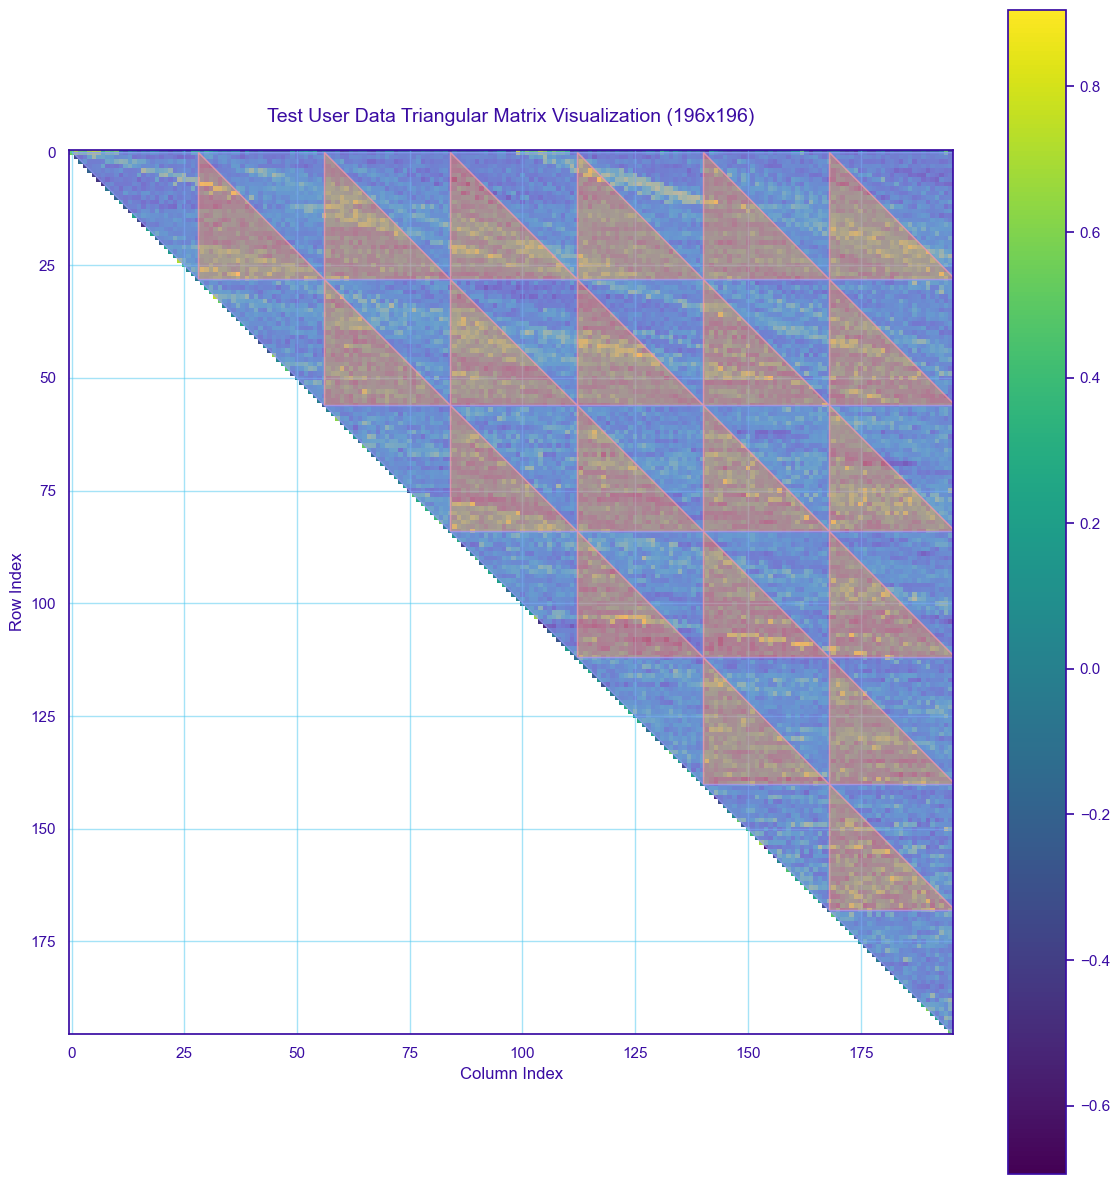

Triangle 1 - Region: Alt | >0.62: 2 | Negative Connections: 7 | Positive Proportion: 0.00 | Negative Proportion: 0.02 | Positive-to-Negative Ratio: 0.29
Triangle 2 - Region: Alt | >0.62: 27 | Negative Connections: 15 | Positive Proportion: 0.03 | Negative Proportion: 0.02 | Positive-to-Negative Ratio: 1.80
Triangle 2 - Region: Üst | >0.62: 18 | Negative Connections: 14 | Positive Proportion: 0.02 | Negative Proportion: 0.02 | Positive-to-Negative Ratio: 1.29
Triangle 3 - Region: Alt | >0.62: 29 | Negative Connections: 4 | Positive Proportion: 0.04 | Negative Proportion: 0.01 | Positive-to-Negative Ratio: 7.25
Triangle 3 - Region: Üst | >0.62: 16 | Negative Connections: 25 | Positive Proportion: 0.02 | Negative Proportion: 0.03 | Positive-to-Negative Ratio: 0.64
Triangle 4 - Region: Alt | >0.62: 33 | Negative Connections: 14 | Positive Proportion: 0.04 | Negative Proportion: 0.02 | Positive-to-Negative Ratio: 2.36
Triangle 4 - Region: Üst | >0.62: 26 | Negative Connections: 31 | Positiv

In [11]:
# Define general parameters
GRID_SIZE = 28  # Size of each square block
MATRIX_SIZE = 196  # Size of the connectivity matrix

UPPER_TRIANGLE_COLOR = (1.0, 0.6, 0.6, 0.6)  # Light red for the upper triangle
LOWER_TRIANGLE_COLOR = (0.6, 0.6, 1.0, 0.6)  # Light blue for the lower triangle

EXCLUDE_TRIANGLE_INDICES = {1, 8, 14, 19, 23, 26, 28}  # Triangle indices to exclude

THRESHOLDS = {
    "positive": 0.46,  # Positive correlation threshold
    "negative": -0.34  # Negative correlation threshold
}
# Function to calculate connectivity statistics for each triangle
def calculate_triangle_statistics(triangle_values, triangle_index, region):

    total_values = len(triangle_values)

    pos_values = np.sum(triangle_values > THRESHOLDS["positive"])
    neg_values = np.sum(triangle_values < THRESHOLDS["negative"])

    pos_ratio = pos_values / total_values if total_values > 0 else np.nan
    neg_ratio = neg_values / total_values if total_values > 0 else np.nan
    pos_neg_ratio = pos_values / neg_values if neg_values > 0 else np.nan

    stats = {
        "Üçgen No": triangle_index,
        "Bölge": region,
        "Pozitif Sayısı": pos_values,
        "Negatif Sayısı": neg_values,
        "Pozitif Oran": pos_ratio,
        "Negatif Oran": neg_ratio,
        "Pozitif/Negatif Oran": pos_neg_ratio
    }

    return stats
# Retrieve the first test participant's connectivity data
first_user_metrics_test_data = metrics_test_data.iloc[0, 1:].values

# Create an empty 196 x 196 matrix filled with NaN values
matrix = np.full((MATRIX_SIZE, MATRIX_SIZE), np.nan)

start_index = 0

for i in range(MATRIX_SIZE):

    num_columns = MATRIX_SIZE - i

    if num_columns > 0:
        matrix[i, i:i + num_columns] = first_user_metrics_test_data[
            start_index:start_index + num_columns
        ]

    start_index += num_columns
plt.figure(figsize=(12, 12))
plt.imshow(matrix, cmap='viridis', interpolation='nearest')
plt.colorbar()
plt.title("Test User Data Triangular Matrix Visualization (196x196)")
plt.xlabel("Column Index")
plt.ylabel("Row Index")
triangle_statistics = []
triangle_index = 1
# Divide the connectivity matrix into smaller blocks
for i in range(0, MATRIX_SIZE - GRID_SIZE + 1, GRID_SIZE):

    for j in range(i, MATRIX_SIZE - GRID_SIZE + 1, GRID_SIZE):

        if j >= i:

            square = matrix[i:i + GRID_SIZE, j:j + GRID_SIZE]

            upper_triangle = np.triu(square)
            lower_triangle = np.tril(square)

            upper_triangle_values = upper_triangle[np.isfinite(upper_triangle)]
            lower_triangle_values = lower_triangle[np.isfinite(lower_triangle)]

            # Check whether the current block lies on the main diagonal
            is_diagonal = (i == j)

            # Calculate lower-triangle statistics
            # Include diagonal blocks and non-excluded blocks
            if is_diagonal or (triangle_index not in EXCLUDE_TRIANGLE_INDICES):

                stats_lower = calculate_triangle_statistics(
                    lower_triangle_values, triangle_index, "Alt"
                )

                triangle_statistics.append(stats_lower)

                plt.gca().add_patch(
                    plt.Polygon(
                        [[j, i], [j + GRID_SIZE, i], [j + GRID_SIZE, i + GRID_SIZE]],
                        color=LOWER_TRIANGLE_COLOR
                    )
                )

            # Calculate upper-triangle statistics
            # Only include blocks that are not on the main diagonal
            if not is_diagonal:

                stats_upper = calculate_triangle_statistics(
                    upper_triangle_values, triangle_index, "Üst"
                )

                triangle_statistics.append(stats_upper)

                plt.gca().add_patch(
                    plt.Polygon(
                        [[j, i], [j, i + GRID_SIZE], [j + GRID_SIZE, i + GRID_SIZE]],
                        color=UPPER_TRIANGLE_COLOR
                    )
                )

            triangle_index += 1
plt.show()
# Display the calculated connectivity statistics
all_statistics = []

for stats in triangle_statistics:

    stat_line = (
        f"Triangle {stats['Üçgen No']} - Region: {stats['Bölge']} | "
        f">0.62: {stats['Pozitif Sayısı']} | "
        f"Negative Connections: {stats['Negatif Sayısı']} | "
        f"Positive Proportion: {stats['Pozitif Oran']:.2f} | "
        f"Negative Proportion: {stats['Negatif Oran']:.2f} | "
        f"Positive-to-Negative Ratio: {stats['Pozitif/Negatif Oran']:.2f}"
    )

    all_statistics.append(stat_line)

print("\n".join(all_statistics))


columns = []

for i in range(1, 29):

    if i in EXCLUDE_TRIANGLE_INDICES and i != 1:
        # Triangle 1 lies on the main diagonal, so only the lower-triangle block is retained
        columns.append(f"Üçgen {i} - Üst")

    else:
        columns.append(f"Üçgen {i} - Alt")

        if i != 1:
            # Diagonal blocks contain only the lower triangle
            columns.append(f"Üçgen {i} - Üst")
df_statistics = pd.DataFrame(triangle_statistics)
df_final = pd.DataFrame(index=df_statistics.columns[2:], columns=columns)
# Add the calculated statistics as rows
for col in columns:

    triangle_no, region = col.split(" - ")
    triangle_no = int(triangle_no.split()[1])

    region_stats = df_statistics[
        (df_statistics["Üçgen No"] == triangle_no) &
        (df_statistics["Bölge"] == region)
    ].drop(columns=["Üçgen No", "Bölge"])

    if not region_stats.empty:
        df_final[col] = region_stats.values.flatten()

# Calculating connectivity statistics for all test participants

In [12]:
from tqdm import tqdm

# Define general parameters
MATRIX_SIZE = 196  # Size of the connectivity matrix
GRID_SIZE = 28  # Size of each square block
EXCLUDE_TRIANGLE_INDICES = {1, 8, 14, 19, 23, 26, 28}  # Triangle indices to exclude

THRESHOLDS = {
    "positive": 0.46,
    "negative": -0.34
}
# Function to calculate connectivity statistics for each triangle
def calculate_triangle_statistics(triangle_values, triangle_index, region, participant_id):

    total_values = len(triangle_values)

    pos_values = np.sum(triangle_values > THRESHOLDS["positive"])
    neg_values = np.sum(triangle_values < THRESHOLDS["negative"])

    pos_ratio = pos_values / total_values if total_values > 0 else np.nan
    neg_ratio = neg_values / total_values if total_values > 0 else np.nan
    pos_neg_ratio = pos_values / neg_values if neg_values > 0 else np.nan

    stats = {
        "Kullanıcı ID": participant_id,
        "Üçgen No - Bölge": f"{triangle_index} - {region}",
        "Pozitif Sayısı": pos_values,
        "Negatif Sayısı": neg_values,
        "Pozitif Oran": pos_ratio,
        "Negatif Oran": neg_ratio,
        "Pozitif/Negatif Oran": pos_neg_ratio
    }

    return stats
# Create a list to store connectivity statistics for all participants
all_users_statistics = []
# Process the connectivity data for each test participant
for user_id in tqdm(range(len(metrics_test_data)), desc="Processing participants"):

    user_metrics_data = metrics_test_data.iloc[user_id, 1:].values

    participant_id = categorical_metrics_test_data['participant_id'].iloc[user_id]

    user_metrics_data = pd.to_numeric(user_metrics_data, errors='coerce')

    # Create an empty matrix filled with NaN values
    matrix = np.full((MATRIX_SIZE, MATRIX_SIZE), np.nan)

    start_index = 0

    for i in range(MATRIX_SIZE):

        num_columns = MATRIX_SIZE - i

        if num_columns > 0:
            matrix[i, i:i + num_columns] = user_metrics_data[
                start_index:start_index + num_columns
            ]

        start_index += num_columns


    # Divide the connectivity matrix into smaller blocks
    triangle_statistics = []
    triangle_index = 1

    for i in range(0, MATRIX_SIZE - GRID_SIZE + 1, GRID_SIZE):

        for j in range(i, MATRIX_SIZE - GRID_SIZE + 1, GRID_SIZE):

            if j >= i:

                square = matrix[i:i + GRID_SIZE, j:j + GRID_SIZE]

                upper_triangle = np.triu(square)
                lower_triangle = np.tril(square)

                upper_triangle_values = upper_triangle[np.isfinite(upper_triangle)]
                lower_triangle_values = lower_triangle[np.isfinite(lower_triangle)]

                # Calculate statistics for the lower triangle
                if triangle_index not in EXCLUDE_TRIANGLE_INDICES:

                    stats_lower = calculate_triangle_statistics(
                        lower_triangle_values,
                        triangle_index,
                        "Alt",
                        participant_id
                    )

                    triangle_statistics.append(stats_lower)

                # Calculate statistics for the upper triangle
                stats_upper = calculate_triangle_statistics(
                    upper_triangle_values,
                    triangle_index,
                    "Üst",
                    participant_id
                )

                triangle_statistics.append(stats_upper)

                triangle_index += 1

    all_users_statistics.extend(triangle_statistics)
df_all_statistics = pd.DataFrame(all_users_statistics)
# Combine the calculated statistics for each test participant
all_users_combined_stats = []
for user_id in range(len(metrics_test_data)):

    participant_id = categorical_metrics_test_data['participant_id'].iloc[user_id]

    # Retrieve the statistics belonging to the current participant
    user_stats = df_all_statistics[
        df_all_statistics['Kullanıcı ID'] == participant_id
    ].copy()

    user_stats.set_index('Üçgen No - Bölge', inplace=True)

    combined_stats = user_stats.T
    combined_stats['Kullanıcı ID'] = participant_id

    all_users_combined_stats.append(combined_stats)


df_final_combined_stats_test = pd.concat(all_users_combined_stats)
# Remove participant ID rows and create a separate feature column
df_final_combined_stats_test.reset_index(inplace=True)
df_final_combined_stats_test.rename(columns={'index': 'Özellik'}, inplace=True)
# Retain participant ID values while combining the cells
df_final_combined_stats_test['Kullanıcı ID'] = df_final_combined_stats_test.apply(
    lambda row: row['Kullanıcı ID'] if row['Özellik'] != 'A' else row['Kullanıcı ID'],
    axis=1
)
# Move the participant ID column to the first position
# Ensure that participant ID does not appear as a feature row
df_final_combined_stats_test = df_final_combined_stats_test[
    df_final_combined_stats_test['Özellik'] != 'Kullanıcı ID'
]
cols = df_final_combined_stats_test.columns.tolist()
cols.insert(0, cols.pop(cols.index('Kullanıcı ID')))
df_final_combined_stats_test = df_final_combined_stats_test[cols]

Processing participants: 100%|██████████| 304/304 [00:06<00:00, 43.93it/s]


# Merging training datasets

In [13]:
# Merge the training datasets
merged_data = categorical_metrics_data.merge(
    quantitative_metrics_data, on="participant_id", how="inner"
).merge(
    solutions_metrics_data, on="participant_id", how="inner"
)
# Remove the target columns
merged_data.drop(columns=['ADHD_Outcome', 'Sex_F'], inplace=True)

In [14]:
# Merge test categorical and quantitative datasets
merged_test_data = categorical_metrics_test_data.merge(
    quantitative_metrics_test_data,
    on="participant_id",
    how="inner"
)
print("Merged test data shape:", merged_test_data.shape)

Merged test data shape: (304, 28)


# Predicting missing MRI scan ages using XGBoost regression

In [15]:
from xgboost import XGBRegressor, DMatrix, train
from xgboost.callback import EarlyStopping
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.preprocessing import LabelEncoder
from sklearn.model_selection import train_test_split
import numpy as np
import pandas as pd

# Define numerical and categorical columns
numeric_columns = [
    "EHQ_EHQ_Total", "ColorVision_CV_Score", "APQ_P_APQ_P_CP", "APQ_P_APQ_P_ID",
    "APQ_P_APQ_P_INV", "APQ_P_APQ_P_OPD", "APQ_P_APQ_P_PM", "APQ_P_APQ_P_PP",
    "SDQ_SDQ_Conduct_Problems", "SDQ_SDQ_Difficulties_Total", "SDQ_SDQ_Emotional_Problems",
    "SDQ_SDQ_Externalizing", "SDQ_SDQ_Generating_Impact", "SDQ_SDQ_Hyperactivity",
    "SDQ_SDQ_Internalizing", "SDQ_SDQ_Peer_Problems", "SDQ_SDQ_Prosocial"
]

categorical_columns = [
    col for col in merged_data.columns
    if col not in numeric_columns + ["MRI_Track_Age_at_Scan", "participant_id"]
]

# Encode categorical columns
label_encoders = {}

for col in categorical_columns:
    le = LabelEncoder()
    merged_data[col] = le.fit_transform(merged_data[col].astype(str))
    label_encoders[col] = le

# Check for missing values in numerical columns
merged_data[numeric_columns] = merged_data[numeric_columns].fillna(
    merged_data[numeric_columns].mean()
)

# Identify missing values in the MRI_Track_Age_at_Scan column
train_data = merged_data[~merged_data["MRI_Track_Age_at_Scan"].isna()]
test_data = merged_data[merged_data["MRI_Track_Age_at_Scan"].isna()]

# Define features (X) and target (y)
X_train = train_data.drop(columns=["MRI_Track_Age_at_Scan", "participant_id"])
y_train = train_data["MRI_Track_Age_at_Scan"]
X_test = test_data.drop(columns=["MRI_Track_Age_at_Scan", "participant_id"])

# Split the data into training and validation sets
X_train, X_val, y_train, y_val = train_test_split(
    X_train, y_train, test_size=0.2, random_state=42
)

# Convert the data into XGBoost DMatrix format
dtrain = DMatrix(X_train, label=y_train)
dval = DMatrix(X_val, label=y_val)
dtest = DMatrix(X_test)

# Define XGBoost model parameters
params = {
    "objective": "reg:squarederror",
    "random_state": 42,
    "subsample": 0.8,
    "colsample_bytree": 0.8,
    "learning_rate": 0.0025,
    "max_depth": 6,
    "n_estimators": 2000
}

# Train the model with early stopping
print("Training the XGBoost regression model...")

xgboost_model = train(
    params,
    dtrain,
    num_boost_round=2000,
    evals=[(dval, "validation")],
    early_stopping_rounds=70,
    verbose_eval=0
)
# Generate predictions for missing values
print("Predicting missing MRI scan ages...")
xgboost_preds = xgboost_model.predict(dtest)
# Evaluate model performance
xgboost_train_preds = xgboost_model.predict(dtrain)
xgboost_train_mse = mean_squared_error(y_train, xgboost_train_preds)
xgboost_train_r2 = r2_score(y_train, xgboost_train_preds)
print(
    f"XGBoost - Training MSE: {xgboost_train_mse:.4f}, "
    f"Training R-squared: {xgboost_train_r2:.4f}"
)

# Fill missing MRI scan age values with predictions
test_data.loc[:, "MRI_Track_Age_at_Scan"] = xgboost_preds
# Combine the data while preserving participant IDs
filled_data = pd.concat([train_data, test_data]).sort_index()

Training the XGBoost regression model...


C:\Users\user\anaconda3\Lib\site-packages\xgboost\callback.py:385: UserWarning: [19:38:24] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:782: 
Parameters: { "n_estimators" } are not used.

  self.starting_round = model.num_boosted_rounds()


Predicting missing MRI scan ages...
XGBoost - Training MSE: 1.6623, Training R-squared: 0.8455


# Displaying the completed dataset

In [16]:
filled_data

,participant_id,Basic_Demos_Enroll_Year,Basic_Demos_Study_Site,PreInt_Demos_Fam_Child_Ethnicity,PreInt_Demos_Fam_Child_Race,MRI_Track_Scan_Location,Barratt_Barratt_P1_Edu,Barratt_Barratt_P1_Occ,Barratt_Barratt_P2_Edu,Barratt_Barratt_P2_Occ,...,SDQ_SDQ_Conduct_Problems,SDQ_SDQ_Difficulties_Total,SDQ_SDQ_Emotional_Problems,SDQ_SDQ_Externalizing,SDQ_SDQ_Generating_Impact,SDQ_SDQ_Hyperactivity,SDQ_SDQ_Internalizing,SDQ_SDQ_Peer_Problems,SDQ_SDQ_Prosocial,MRI_Track_Age_at_Scan
0,00aIpNTbG5uh,4,3,1,0,2,3,8,7,10,...,3.0,17.0,4.0,11.0,5.0,8.0,6.0,2.0,9.0,14.274127
1,00fV0OyyoLfw,2,0,0,9,1,3,0,3,8,...,5.0,20.0,4.0,13.0,5.0,8.0,7.0,3.0,8.0,13.340958
2,04X1eiS79T4B,2,0,1,4,1,6,0,7,10,...,3.0,24.0,7.0,10.0,10.0,7.0,14.0,7.0,7.0,13.463381
3,05ocQutkURd6,3,0,3,8,1,2,1,2,0,...,0.0,5.0,0.0,3.0,0.0,3.0,2.0,2.0,6.0,9.572553
4,06YUNBA9ZRLq,3,0,0,1,1,0,0,7,10,...,6.0,23.0,7.0,15.0,8.0,9.0,8.0,1.0,4.0,6.654574
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1208,zwjJWCRzKhDz,4,3,1,1,2,0,10,1,9,...,5.0,20.0,5.0,13.0,5.0,8.0,7.0,2.0,8.0,11.272986
1209,zwXD5v17Rx01,3,0,0,0,2,3,7,3,7,...,2.0,5.0,0.0,5.0,0.0,3.0,0.0,0.0,7.0,7.364020
1210,zWzLCi3NTBTd,3,2,2,5,2,3,7,3,6,...,2.0,14.0,3.0,9.0,3.0,7.0,5.0,2.0,9.0,9.962126
1211,Zy9GTHDxUbXU,4,3,0,1,2,2,6,2,8,...,1.0,10.0,0.0,8.0,5.0,7.0,2.0,2.0,7.0,8.785126


# Combining training data with connectivity features

In [17]:
# Pivot the connectivity statistics into a participant-level feature table
pivot_df = df_final_combined_stats.pivot(
    index='Kullanıcı ID',
    columns='Özellik'
)
# Rename the resulting columns
pivot_df.columns = [f"{col[0]}_{col[1]}" for col in pivot_df.columns]
pivot_df.reset_index(inplace=True)
# Merge the datasets using participant IDs
combined_df = pd.merge(
    filled_data,
    pivot_df,
    left_on='participant_id',
    right_on='Kullanıcı ID'
)
combined_df.drop(columns=['Kullanıcı ID'], inplace=True)

# Combining test data with connectivity features

In [18]:
# Pivot the test connectivity statistics into a participant-level feature table
pivot_test_df = df_final_combined_stats_test.pivot(
    index='Kullanıcı ID',
    columns='Özellik'
)
# Rename the resulting columns
pivot_test_df.columns = [f"{col[0]}_{col[1]}" for col in pivot_test_df.columns]
pivot_test_df.reset_index(inplace=True)
# Merge the datasets using participant IDs
combined_test_df = pd.merge(
    merged_test_data,
    pivot_test_df,
    left_on='participant_id',
    right_on='Kullanıcı ID'
)
combined_test_df.drop(columns=['Kullanıcı ID'], inplace=True)
combined_test_df.fillna(0, inplace=True)

C:\Users\user\AppData\Local\Temp\ipykernel_12944\461981824.py:17: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  combined_test_df.fillna(0, inplace=True)


# Creating the final training dataset

In [19]:
# Merge the engineered training features with the diagnostic labels
final_combined_df = pd.merge(
    combined_df,
    solutions_metrics_data,
    on='participant_id'
)
final_combined_df.fillna(0, inplace=True)

C:\Users\user\AppData\Local\Temp\ipykernel_12944\3437380890.py:7: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  final_combined_df.fillna(0, inplace=True)


# Checking missing values in the combined datasets

In [20]:
missing_combined_test = combined_test_df.isnull().sum().sum()
print(
    f"Total missing values in the combined test dataset: "
    f"{missing_combined_test}"
)
missing_final_combined = final_combined_df.isnull().sum().sum()
print(
    f"Total missing values in the final combined training dataset: "
    f"{missing_final_combined}"
)

Total missing values in the combined test dataset: 0
Total missing values in the final combined training dataset: 0


# Calculating average connectivity statistics

In [21]:
# Define keywords corresponding to the connectivity statistics
column_keywords = [
    'Pozitif Sayısı',
    'Negatif Sayısı',
    'Pozitif Oran',
    'Negatif Oran'
]
column_keywords2 = [
    'Pozitif Sayısı',
    'Negatif Sayısı',
    'Pozitif Oran',
    'Negatif Oran'
]
# Function to calculate group averages
def calculate_group_means(df, keywords):

    means = {}

    for keyword in keywords:

        # Select columns containing the specified keyword
        relevant_columns = [
            col for col in df.columns if keyword in col
        ]

        if relevant_columns:

            group_mean = df[relevant_columns].mean().mean()
            means[keyword] = group_mean

        else:
            means[keyword] = None

    return means
# Function to calculate group averages
def calculate_group_means(df, keywords2):

    means = {}

    for keyword2 in keywords2:

        # Select columns containing the specified keyword
        relevant_columns = [
            col for col in df.columns if keyword2 in col
        ]

        if relevant_columns:

            # Calculate the mean of the selected columns and then their overall mean
            group_mean = df[relevant_columns].mean().mean()
            means[keyword2] = group_mean

        else:

            # Return None if no matching columns are found
            means[keyword2] = None

    return means
# Calculate the connectivity statistics
combined_means = calculate_group_means(
    combined_test_df,
    column_keywords
)

final_means = calculate_group_means(
    final_combined_df,
    column_keywords2
)
print("Average Connectivity Statistics in the Combined Test Dataset:")
for keyword, mean in combined_means.items():
    print(f"{keyword}: {mean}")
print("\nAverage Connectivity Statistics in the Final Combined Training Dataset:")

for keyword, mean in final_means.items():
    print(f"{keyword}: {mean}")

Average Connectivity Statistics in the Combined Test Dataset:
Pozitif Sayısı: 24.912459720730396
Negatif Sayısı: 24.20743823845328
Pozitif Oran: 0.03177609658256428
Negatif Oran: 1.0308319111786497

Average Connectivity Statistics in the Final Combined Training Dataset:
Pozitif Sayısı: 24.98739842185844
Negatif Sayısı: 24.76926830089002
Pozitif Oran: 0.031871681660533724
Negatif Oran: 0.9416168517077783


# Assigning the final training and test datasets

In [22]:
test_df = combined_test_df
train_df = final_combined_df

# Removing the study-site column

In [23]:
# Remove the basic_demos_study_site column from both training and test DataFrames
train_df = train_df.drop(
    columns=['basic_demos_study_site'],
    errors='ignore'
)
test_df = test_df.drop(
    columns=['basic_demos_study_site'],
    errors='ignore'
)

# Creating additional features and scaling connectivity variables

In [24]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler, LabelEncoder
def preprocess_data(df):

    # 1. Create combinations of demographic and study-site variables
    combinations = {

        'Basic_Demos_Study_Site-PreInt_Demos_Fam_Child_Ethnicity':
            df['Basic_Demos_Study_Site'].astype(str) + '-' +
            df['PreInt_Demos_Fam_Child_Ethnicity'].astype(str),

        'PreInt_Demos_Fam_Child_Ethnicity-MRI_Track_Scan_Location':
            df['PreInt_Demos_Fam_Child_Ethnicity'].astype(str) + '-' +
            df['MRI_Track_Scan_Location'].astype(str),

        'Basic_Demos_Study_Site-MRI_Track_Scan_Location':
            df['Basic_Demos_Study_Site'].astype(str) + '-' +
            df['MRI_Track_Scan_Location'].astype(str)
    }

    # Add the combination columns to the DataFrame
    df = pd.concat(
        [df, pd.DataFrame(combinations)],
        axis=1
    )


    # 2. Encode the newly created combination columns
    label_encoders = {}

    combination_columns = list(combinations.keys())

    for col in combination_columns:

        le = LabelEncoder()

        df[col] = le.fit_transform(df[col])

        label_encoders[col] = le


    # 3. Create a categorical variable based on EHQ scores
    conditions = [

        df['EHQ_EHQ_Total'] == -100,  # Extremely left-handed
        (df['EHQ_EHQ_Total'] >= -28) & (df['EHQ_EHQ_Total'] < 48),  # Middle range
        df['EHQ_EHQ_Total'] == 100,  # Extremely right-handed
        df['EHQ_EHQ_Total'] > 48,  # Greater than 48
        df['EHQ_EHQ_Total'] < -28  # Less than -28
    ]

    choices = [

        'left',
        'middle',
        'right',
        'greater_than_48',
        'less_than_minus_28'
    ]

    df['EHQ_Category'] = np.select(
        conditions,
        choices,
        default='unknown'
    )


    # 4. Encode the EHQ category variable
    le_ehq = LabelEncoder()

    df['EHQ_Category_Encoded'] = le_ehq.fit_transform(
        df['EHQ_Category']
    )

    label_encoders['EHQ_Category'] = le_ehq


    # 5. Identify connectivity features to be scaled
    columns_to_scale = []

    for i in range(1, 29):

        columns_to_scale.extend([
            f'{i} - Üst_Negatif Sayısı',
            f'{i} - Üst_Pozitif Sayısı',
            f'{i} - Üst_Pozitif Oran',
            f'{i} - Üst_Pozitif/Negatif Oran'
        ])


    columns_to_scale = [
        col for col in columns_to_scale
        if col in df.columns
    ]


    # 6. Scale the selected connectivity features between -1 and 1
    scaler = MinMaxScaler(feature_range=(-1, 1))

    df[columns_to_scale] = scaler.fit_transform(
        df[columns_to_scale]
    )

    return df, label_encoders
train_df, label_encoders = preprocess_data(train_df)
test_df, _ = preprocess_data(test_df)
train_df.drop(columns=["EHQ_Category"], inplace=True)

In [25]:
# Inspecting the final training dataset
train_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1213 entries, 0 to 1212
Columns: 279 entries, participant_id to EHQ_Category_Encoded
dtypes: float64(221), int64(57), object(1)
memory usage: 2.6+ MB


# XGBoost ADHD classification and five-fold cross-validation

In [28]:

import numpy as np
import pandas as pd
from pathlib import Path
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    roc_auc_score,
    matthews_corrcoef
)
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.utils.class_weight import compute_class_weight
import xgboost as xgb
from collections import defaultdict
import warnings

warnings.filterwarnings('ignore')

# Set the local output directory
OUTPUT_DIR = Path(r"C:\Users\user\Desktop\Python")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


# Calculate Matthews Correlation Coefficient
def mcc_eval(y_true, y_pred):
    y_pred_labels = (y_pred > 0.5).astype(int)
    mcc = matthews_corrcoef(y_true, y_pred_labels)
    return 'mcc', mcc, True


# Record classification performance metrics
def log_metrics(y_true, y_pred, y_probs, fold_results):
    fold_results['Accuracy'].append(
        accuracy_score(y_true, y_pred)
    )
    fold_results['F1'].append(
        f1_score(y_true, y_pred)
    )
    fold_results['AUC_ROC'].append(
        roc_auc_score(y_true, y_probs)
    )
    fold_results['MCC'].append(
        matthews_corrcoef(y_true, y_pred)
    )


# Calculate class weights to address class imbalance
def calculate_class_weights(y):
    unique_classes = np.unique(y)
    weights = compute_class_weight(
        class_weight='balanced',
        classes=unique_classes,
        y=y
    )
    return dict(zip(unique_classes, weights))


# Prepare training and test data
def prepare_data(train_df, test_df):

    categorical_columns = [
        "Basic_Demos_Enroll_Year",
        "Basic_Demos_Study_Site",
        "PreInt_Demos_Fam_Child_Ethnicity",
        "PreInt_Demos_Fam_Child_Race",
        "MRI_Track_Scan_Location",
        "Barratt_Barratt_P1_Occ",
        "Barratt_Barratt_P2_Edu",
        "Barratt_Barratt_P2_Occ",
        "Basic_Demos_Study_Site-PreInt_Demos_Fam_Child_Ethnicity",
        "PreInt_Demos_Fam_Child_Ethnicity-MRI_Track_Scan_Location",
        "Basic_Demos_Study_Site-MRI_Track_Scan_Location",
        "EHQ_Category_Encoded"
    ]

    numeric_columns = [
        col for col in train_df.columns
        if col not in categorical_columns + [
            "ADHD_Outcome",
            "Sex_F",
            "participant_id"
        ]
    ]

    preprocessor = ColumnTransformer([
        ('num', StandardScaler(), numeric_columns),
        (
            'cat',
            OneHotEncoder(
                handle_unknown='ignore',
                sparse_output=False
            ),
            categorical_columns
        )
    ])

    X = preprocessor.fit_transform(train_df)
    X_test = preprocessor.transform(test_df)

    feature_names = (
        numeric_columns
        + preprocessor.named_transformers_['cat']
        .get_feature_names_out(categorical_columns).tolist()
    )

    return X, X_test, preprocessor, feature_names


# Extract the ADHD target variable
def create_target(train_df):
    return train_df["ADHD_Outcome"].values


# Train and evaluate XGBoost using five-fold cross-validation
def train_and_evaluate(
    X, y, X_test, test_df, feature_names, params
):

    skf = StratifiedKFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )

    fold_results = defaultdict(list)
    combined_predictions_all = []
    feature_importance_dict = defaultdict(float)

    for fold, (train_idx, val_idx) in enumerate(
        skf.split(X, y), 1
    ):

        print(f"\n{'='*40}")
        print(f"Fold {fold}/5 Training...")
        print(f"{'='*40}")

        X_train, X_val = X[train_idx], X[val_idx]
        y_train, y_val = y[train_idx], y[val_idx]

        # Calculate class weights for the current fold
        class_weights = calculate_class_weights(y_train)

        sample_weights = np.array([
            class_weights[yi] for yi in y_train
        ])

        # Initialize the XGBoost classifier
        model = xgb.XGBClassifier(
            **params,
            n_estimators=1500,
            early_stopping_rounds=200,
            enable_categorical=False
        )

        # Train the model
        model.fit(
            X_train,
            y_train,
            sample_weight=sample_weights,
            eval_set=[(X_val, y_val)],
            verbose=False
        )

        # Record feature importance
        importance = model.feature_importances_

        for idx, score in enumerate(importance):
            feature_name = feature_names[idx]
            feature_importance_dict[feature_name] += score

        # Generate validation predictions
        val_probs = model.predict_proba(X_val)[:, 1]
        val_preds = (val_probs > 0.5).astype(int)

        # Calculate performance metrics
        log_metrics(
            y_val,
            val_preds,
            val_probs,
            fold_results
        )

        print(f"\nFold {fold} Results:")
        print(
            f"Accuracy: {fold_results['Accuracy'][-1]:.4f}"
        )
        print(f"F1: {fold_results['F1'][-1]:.4f}")
        print(
            f"AUC-ROC: {fold_results['AUC_ROC'][-1]:.4f}"
        )
        print(f"MCC: {fold_results['MCC'][-1]:.4f}")

        # Generate predictions for the test dataset
        test_probs = model.predict_proba(X_test)[:, 1]
        combined_predictions_all.append(test_probs)

    final_threshold = 0.5

    feature_importance_avg = {
        k: v / 5
        for k, v in feature_importance_dict.items()
    }

    return (
        fold_results,
        combined_predictions_all,
        final_threshold,
        feature_importance_avg
    )


# Display average cross-validation results
def print_ensemble_results(results):

    print("\n\n" + "="*50)
    print("Final Ensemble Results (5-Fold Average ± Std):")
    print("="*50)

    metrics = ['Accuracy', 'F1', 'AUC_ROC', 'MCC']

    for metric in metrics:
        mean = np.mean(results[metric])
        std = np.std(results[metric])

        print(f"{metric}: {mean:.4f} ± {std:.4f}")


# Save predictions for all test participants
def save_all_predictions(
    test_df, predictions_list, threshold
):

    submission_df = pd.DataFrame({
        'participant_id': test_df['participant_id']
    })

    for i, preds in enumerate(predictions_list, 1):
        submission_df[f'ADHD_Outcome_Model_{i}'] = (
            preds >= threshold
        ).astype(int)

    # Preserve the original participant order
    test_participants = test_df[
        ['participant_id']
    ].drop_duplicates()

    submission_df_sorted = test_participants.merge(
        submission_df,
        on='participant_id',
        how='left'
    )

    if submission_df_sorted.isnull().any().any():
        print(
            "Warning: Some test participants have missing predictions."
        )
        submission_df_sorted.fillna(0, inplace=True)

    # Save predictions to the local output directory
    prediction_path = (
        OUTPUT_DIR / "submission_multiple_models_xgb.xlsx"
    )

    submission_df_sorted.to_excel(
        prediction_path,
        index=False
    )

    print(
        f"XGBoost predictions saved to: {prediction_path}"
    )

    return submission_df_sorted['ADHD_Outcome_Model_1'].values


# Main XGBoost modelling function
def main(train_df, test_df):

    X, X_test, preprocessor, feature_names = prepare_data(
        train_df,
        test_df
    )

    y = create_target(train_df)

    # Define the researcher's original hyperparameters
    model_params = {
        'learning_rate': 0.05600623106477138,
        'max_depth': 10,
        'min_child_weight': 0.001753139198397266,
        'subsample': 0.8556823379046696,
        'colsample_bytree': 0.7104719442915508,
        'reg_lambda': 3.6831497086151286,
        'reg_alpha': 0.16347733288433106,
        'objective': 'binary:logistic',
        'eval_metric': 'logloss',
        'random_state': 42,
        'tree_method': 'hist',
        'device': 'cpu',
        'n_jobs': 2
    }

    print("Training XGBoost model using CPU...")

    (
        fold_results,
        combined_predictions_all,
        final_threshold,
        feature_importance_avg
    ) = train_and_evaluate(
        X,
        y,
        X_test,
        test_df,
        feature_names,
        model_params
    )

    # Display cross-validation results
    print_ensemble_results(fold_results)

    # Combine predictions from all five folds
    combined_ensemble_pred = np.mean(
        combined_predictions_all,
        axis=0
    )

    all_predictions = [combined_ensemble_pred]

    # Save feature importance scores
    feature_importance_df = pd.DataFrame({
        'Feature': list(feature_importance_avg.keys()),
        'Importance': list(feature_importance_avg.values())
    }).sort_values(
        by='Importance',
        ascending=False
    )

    feature_importance_path = (
        OUTPUT_DIR / 'feature_importance_xgb_f1.xlsx'
    )

    feature_importance_df.to_excel(
        feature_importance_path,
        index=False
    )

    print(
        f"Feature importance saved to: {feature_importance_path}"
    )

    # Save test predictions
    save_all_predictions(
        test_df,
        all_predictions,
        final_threshold
    )
# Run the model using the training and test datasets
main(train_df, test_df)


Training XGBoost model using CPU...

Fold 1/5 Training...

Fold 1 Results:
Accuracy: 0.8107
F1: 0.8663
AUC-ROC: 0.8605
MCC: 0.5460

Fold 2/5 Training...

Fold 2 Results:
Accuracy: 0.7942
F1: 0.8538
AUC-ROC: 0.8176
MCC: 0.5101

Fold 3/5 Training...

Fold 3 Results:
Accuracy: 0.7860
F1: 0.8471
AUC-ROC: 0.7921
MCC: 0.4931

Fold 4/5 Training...

Fold 4 Results:
Accuracy: 0.7893
F1: 0.8468
AUC-ROC: 0.8548
MCC: 0.5091

Fold 5/5 Training...

Fold 5 Results:
Accuracy: 0.7355
F1: 0.8129
AUC-ROC: 0.7961
MCC: 0.3653


Final Ensemble Results (5-Fold Average ± Std):
Accuracy: 0.7831 ± 0.0253
F1: 0.8454 ± 0.0177
AUC_ROC: 0.8242 ± 0.0287
MCC: 0.4847 ± 0.0622
Feature importance saved to: C:\Users\user\Desktop\Python\feature_importance_xgb_f1.xlsx
XGBoost predictions saved to: C:\Users\user\Desktop\Python\submission_multiple_models_xgb.xlsx


# Ridge Classifier with multi-output prediction

In [29]:
import numpy as np
import pandas as pd
from sklearn.metrics import f1_score
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.pipeline import make_pipeline, Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, FunctionTransformer, MinMaxScaler
from sklearn.impute import SimpleImputer
from sklearn.decomposition import PCA
from sklearn.linear_model import RidgeClassifier
from sklearn.multioutput import MultiOutputClassifier
import matplotlib.pyplot as plt
import seaborn as sns
import scipy


# Load the datasets
def load_data():

    # Load training datasets
    train_quant = pd.read_excel(
       r"C:\Users\user\Desktop\Python\TRAIN_OLD\TRAIN_QUANTITATIVE_METADATA.xlsx"
    )

    train_cate = pd.read_excel(
        r"C:\Users\user\Desktop\Python\TRAIN_OLD\TRAIN_CATEGORICAL_METADATA.xlsx"
    )

    train_func = pd.read_csv(
        r"C:\Users\user\Desktop\Python\TRAIN_OLD\TRAIN_FUNCTIONAL_CONNECTOME_MATRICES.csv"
    )

    train_sol = pd.read_excel(
        r"C:\Users\user\Desktop\Python\TRAIN_OLD\TRAINING_SOLUTIONS.xlsx"
    )


    # Load test datasets
    test_quant = pd.read_excel(
        r"C:\Users\user\Desktop\Python\TEST\TEST_QUANTITATIVE_METADATA.xlsx"
    )

    test_cate = pd.read_excel(
        r"C:\Users\user\Desktop\Python\TEST\TEST_CATEGORICAL.xlsx"
    )

    test_func = pd.read_csv(
        r"C:\Users\user\Desktop\Python\TEST\TEST_FUNCTIONAL_CONNECTOME_MATRICES.csv"
    )


    # Merge the training datasets
    train = train_quant.merge(
        train_cate,
        on='participant_id',
        how='left'
    )

    train = train.merge(
        train_func,
        on='participant_id',
        how='left'
    )

    train = train.merge(
        train_sol,
        on='participant_id',
        how='left'
    ).set_index('participant_id')


    # Merge the test datasets
    test = test_quant.merge(
        test_cate,
        on='participant_id',
        how='left'
    )

    test = test.merge(
        test_func,
        on='participant_id',
        how='left'
    ).set_index('participant_id')

    return train, test


# Load the datasets
train, test = load_data()
sub = pd.read_excel(
    r"C:\Users\user\Desktop\Python\SAMPLE_SUBMISSION.xlsx"
)
# Define target variables and input features
targets = ['ADHD_Outcome', 'Sex_F']
features = test.columns
# Identify features that will undergo logarithmic transformation
log_features = [
    f for f in features
    if (train[f] >= 0).all() and scipy.stats.skew(train[f]) > 0
]

# Define the Ridge Classifier pipeline
model = MultiOutputClassifier(make_pipeline(

    ColumnTransformer(
        [('imputer', SimpleImputer(), features)],
        remainder='passthrough',
        verbose_feature_names_out=False
    ).set_output(transform='pandas'),

    ColumnTransformer(
        [('log', FunctionTransformer(np.log1p), log_features)],
        remainder='passthrough'
    ),

    MinMaxScaler(),

    RidgeClassifier(alpha=12.65)
))
# Perform five-fold cross-validation
skf = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)
f1_scores = {t: [] for t in targets}

X = train.drop(targets, axis=1)
y = train[targets]

# Train and evaluate the model in each fold
print("5-Fold Cross-Validation Results:")

for fold, (train_idx, val_idx) in enumerate(
    skf.split(X, y['ADHD_Outcome'])
):

    # Separate training and validation data
    # Stratification is performed using ADHD_Outcome
    X_train, X_val = X.iloc[train_idx], X.iloc[val_idx]
    y_train, y_val = y.iloc[train_idx], y.iloc[val_idx]

    # Train the model
    model.fit(X_train, y_train)

    # Generate predictions
    y_pred = model.predict(X_val)

    # Calculate the F1-score for each target variable
    for i, target in enumerate(targets):

        f1 = f1_score(
            y_val[target],
            y_pred[:, i],
            average='micro'
        )

        f1_scores[target].append(f1)

        print(
            f"Fold {fold+1}, {target} F1 Score: {f1:.4f}"
        )
# Calculate the mean and standard deviation of the F1-scores
print("\nSummary of 5-Fold Cross-Validation:")

for target in targets:

    mean_f1 = np.mean(f1_scores[target])
    std_f1 = np.std(f1_scores[target])

    print(
        f"{target} - Average F1 Score: "
        f"{mean_f1:.4f} ± {std_f1:.4f}"
    )
# Define the PCA-based model for test predictions
model_with_pca = MultiOutputClassifier(make_pipeline(

    ColumnTransformer(
        [('imputer', SimpleImputer(), features)],
        remainder='passthrough',
        verbose_feature_names_out=False
    ).set_output(transform='pandas'),

    ColumnTransformer(
        [('log', FunctionTransformer(np.log1p), log_features)],
        remainder='passthrough'
    ),

    MinMaxScaler(),

    PCA(n_components=1213),

    RidgeClassifier(alpha=12.65)
))
# Train the model using the complete training dataset
model_with_pca.fit(
    train.drop(targets, axis=1),
    train[targets]
)
# Generate predictions for the test dataset
y_pred = model_with_pca.predict(test)
# Prepare the submission file
sub['ADHD_Outcome'] = y_pred[:, 0]
sub['Sex_F'] = y_pred[:, 1]

5-Fold Cross-Validation Results:
Fold 1, ADHD_Outcome F1 Score: 0.7449
Fold 1, Sex_F F1 Score: 0.7490
Fold 2, ADHD_Outcome F1 Score: 0.7531
Fold 2, Sex_F F1 Score: 0.7078
Fold 3, ADHD_Outcome F1 Score: 0.7366
Fold 3, Sex_F F1 Score: 0.6790
Fold 4, ADHD_Outcome F1 Score: 0.7479
Fold 4, Sex_F F1 Score: 0.7521
Fold 5, ADHD_Outcome F1 Score: 0.7438
Fold 5, Sex_F F1 Score: 0.7314

Summary of 5-Fold Cross-Validation:
ADHD_Outcome - Average F1 Score: 0.7453 ± 0.0054
Sex_F - Average F1 Score: 0.7239 ± 0.0274
